In [1]:
!pip install -q shap

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import shap

from tensorflow.keras import layers, models, datasets
from keras.preprocessing.image import load_img, img_to_array
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, Flatten, BatchNormalization
from keras.applications import MobileNetV2

import requests
import zipfile
from typing import Literal

In [3]:
# Criar a pasta para armazenar o dataset
folder = "/content/fer2013"
os.makedirs(folder, exist_ok=True)

# URL do dataset no Kaggle
url = "https://www.kaggle.com/api/v1/datasets/download/msambare/fer2013"

# Baixar o arquivo ZIP
response = requests.get(url, stream=True)
response.raise_for_status()

zip_file = f"{folder}/fer2013.zip"

with open(zip_file, "wb") as file_:
    for block in response.iter_content(chunk_size=1024 * 1024):
        if block:
            file_.write(block)

print("Download concluído!")

Download concluído!


In [4]:
# Descompactar arquivo ZIP
with zipfile.ZipFile("/content/fer2013/fer2013.zip", "r") as file_:
    file_.extractall("/content/fer2013")

print("Dataset extraído com sucesso!")

for root, folders, felis in os.walk("/content/fer2013"):
    level = root.replace("/content/fer2013", "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

Dataset extraído com sucesso!
fer2013/
  test/
    neutral/
    disgust/
    sad/
    angry/
    fear/
    happy/
    surprise/
  train/
    neutral/
    disgust/
    sad/
    angry/
    fear/
    happy/
    surprise/


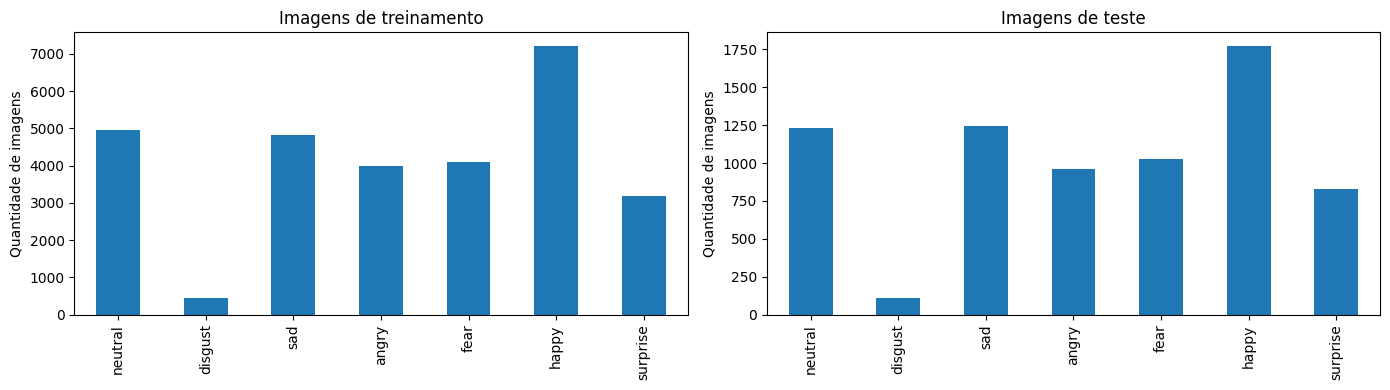

Imagens de treinamento: {'neutral': 4965, 'disgust': 436, 'sad': 4830, 'angry': 3995, 'fear': 4097, 'happy': 7215, 'surprise': 3171}
Imagens de teste: {'neutral': 1233, 'disgust': 111, 'sad': 1247, 'angry': 958, 'fear': 1024, 'happy': 1774, 'surprise': 831}


In [5]:
train_dir = '/content/fer2013/train/'
test_dir = '/content/fer2013/test/'

# Contar imagens de treinamento
train_count = {class_: len(os.listdir(os.path.join(train_dir, class_)))
               for class_ in os.listdir(train_dir)}

# Contar imagens de teste
test_count = {class_: len(os.listdir(os.path.join(test_dir, class_)))
              for class_ in os.listdir(test_dir)}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(train_count).plot(kind="bar", ax=axes[0], title="Imagens de treinamento")
pd.Series(test_count).plot(kind="bar", ax=axes[1], title="Imagens de teste")
axes[0].set_ylabel("Quantidade de imagens")
axes[1].set_ylabel("Quantidade de imagens")
plt.tight_layout()
plt.show()

print("Imagens de treinamento:", train_count)
print("Imagens de teste:", test_count)


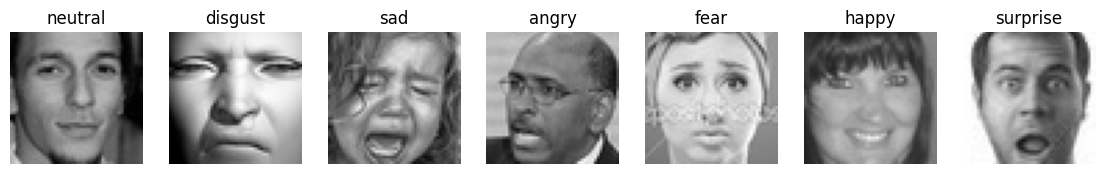

In [6]:
plt.figure(figsize=(14,4))
i = 1
for expression in os.listdir(train_dir):
    img = load_img((train_dir + expression +'/'+ os.listdir(train_dir + expression)[5]))
    plt.subplot(1,7,i)
    plt.imshow(img)
    plt.title(expression)
    plt.axis('off')
    i += 1
plt.show()

In [7]:
# Carregar os conjuntos de treino e teste
def carregar_imagens(path_dir):
    imagens = []
    rotulos = []
    mapping = {
    'angry': 0, 'disgust': 1, 'fear': 2,
    'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6
}
    for emocao, rotulo in mapping.items():
        pasta = os.path.join(path_dir, emocao)
        for arquivo in os.listdir(pasta):
            caminho = os.path.join(pasta, arquivo)
            if os.path.isfile(caminho):
                  imagem = load_img(caminho, target_size=(48, 48), color_mode="grayscale")
                  imagens.append(img_to_array(imagem))
                  rotulos.append(rotulo)
    return np.array(imagens, dtype=np.float32) / 255.0, np.array(rotulos, dtype=np.int32)

X_train_dataset, y_train_dataset = carregar_imagens(train_dir)
X_test, y_test = carregar_imagens(test_dir)


print("Imagens para treinamento:", len(X_train_dataset))
print("Imagens para teste:", len(X_test))

Imagens para treinamento: 28709
Imagens para teste: 7178


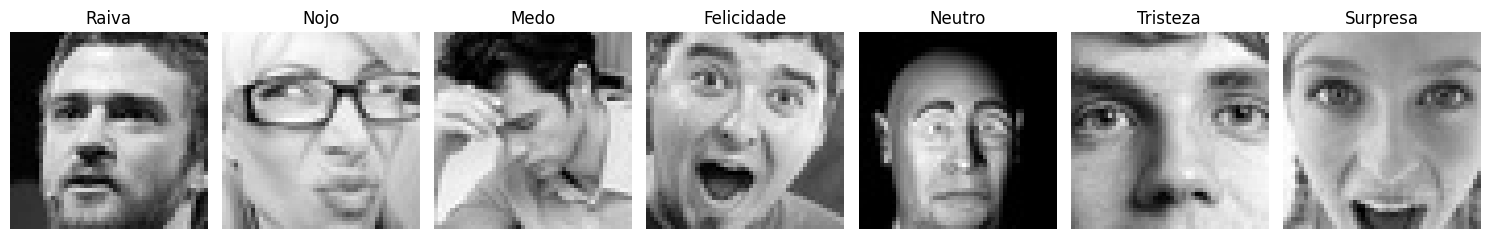

In [8]:
classes = ['Raiva', 'Nojo', 'Medo', 'Felicidade', 'Neutro', 'Tristeza', 'Surpresa']

first_image_index = {}
for i, label in enumerate(y_train_dataset):
    first_image_index.setdefault(label, i)

fig, axes = plt.subplots(1, 7, figsize=(15, 4))

for i, ax in enumerate(axes):
    ax.imshow(X_train_dataset[first_image_index[i]].reshape(48, 48), cmap='gray')
    ax.set_title(classes[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [9]:
# Separar treinamento e validação mantendo a proporção das classes
X_train, X_val, y_train, y_val = train_test_split(
    X_train_dataset, y_train_dataset, test_size=0.2, random_state=42, stratify=y_train_dataset
)

print("Imagens para treinamento:", len(X_train))
train_count = {class_: len(np.where(y_train == i)[0]) for i, class_ in enumerate(classes)}
print("Imagens de treinamento por classe:", train_count)
print("Imagens para validação:", len(X_val))
val_count = {class_: len(np.where(y_val == i)[0]) for i, class_ in enumerate(classes)}
print("Imagens de validação por classe:", val_count)


Imagens para treinamento: 22967
Imagens de treinamento por classe: {'Raiva': 3196, 'Nojo': 349, 'Medo': 3277, 'Felicidade': 5772, 'Neutro': 3972, 'Tristeza': 3864, 'Surpresa': 2537}
Imagens para validação: 5742
Imagens de validação por classe: {'Raiva': 799, 'Nojo': 87, 'Medo': 820, 'Felicidade': 1443, 'Neutro': 993, 'Tristeza': 966, 'Surpresa': 634}


In [10]:
target_samples = 7000
unique_classes, class_counts = np.unique(y_train, return_counts=True)

print("Quantidades originais por classe no treino:", dict(zip(unique_classes, class_counts)))

X_train_balanced_list = []
y_train_balanced_list = []

for classe in unique_classes:
    indices = np.where(y_train == classe)[0]

    indices_replicados = np.random.choice(indices, size=target_samples, replace=True)

    X_train_balanced_list.append(X_train[indices_replicados])
    y_train_balanced_list.append(y_train[indices_replicados])

X_train_balanced = np.concatenate(X_train_balanced_list, axis=0)
y_train_balanced = np.concatenate(y_train_balanced_list, axis=0)

shuffle_indices = np.random.permutation(len(y_train_balanced))
X_train_balanced = X_train_balanced[shuffle_indices]
y_train_balanced = y_train_balanced[shuffle_indices]

unique_balanced, counts_balanced = np.unique(y_train_balanced, return_counts=True)
print("Nova distribuição de classes no treino:", dict(zip(unique_balanced, counts_balanced)))
print(f"Total de imagens no treino após a replicação: {len(y_train_balanced)}")

Quantidades originais por classe no treino: {np.int32(0): np.int64(3196), np.int32(1): np.int64(349), np.int32(2): np.int64(3277), np.int32(3): np.int64(5772), np.int32(4): np.int64(3972), np.int32(5): np.int64(3864), np.int32(6): np.int64(2537)}
Nova distribuição de classes no treino: {np.int32(0): np.int64(7000), np.int32(1): np.int64(7000), np.int32(2): np.int64(7000), np.int32(3): np.int64(7000), np.int32(4): np.int64(7000), np.int32(5): np.int64(7000), np.int32(6): np.int64(7000)}
Total de imagens no treino após a replicação: 49000


In [11]:
classes = np.unique(y_train)

pesos = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, pesos))

print(class_weights)

{np.int32(0): np.float64(1.0265957446808511), np.int32(1): np.float64(9.401146131805158), np.int32(2): np.float64(1.0012206286237413), np.int32(3): np.float64(0.5684338184338185), np.int32(4): np.float64(0.8260322255790534), np.int32(5): np.float64(0.849120082815735), np.int32(6): np.float64(1.2932597556168703)}


In [12]:
# Definir dimensões da imagem
image_height = 48
image_width = 48
resized_size = 96

# Criar o modelo
base_model = MobileNetV2(input_shape=(resized_size, resized_size, 1), include_top=False, weights=None, pooling='avg')

# Ajustar o momentum do BatchNormalization (padrão 0.999 é lento para treino do zero)
for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.momentum = 0.9

model = Sequential()

model.add(layers.Input(shape=(image_height, image_width, 1)))
model.add(layers.Resizing(resized_size, resized_size)) # Aumenta 48x48 -> 96x96
model.add(base_model)

model.add(Flatten())
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.2)) # Adiciona a camada de dropout
model.add(Dense(7, activation='softmax')) # Especifica 'softmax' como a função de ativação

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 1280)           │     2,257,408 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        40,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,298,631 (8.77 MB)

 Trainable params: 2,264,519 (8.64 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [13]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_cnn_emotion.weights.h5",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)


Epoch 1/200
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.2235 - loss: 1.8851
Epoch 1: val_loss improved from None to 1.76046, saving model to best_cnn_emotion.weights.h5

Epoch 1: finished saving model to best_cnn_emotion.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 114s 156ms/step - accuracy: 0.2376 - loss: 1.8396 - val_accuracy: 0.2875 - val_loss: 1.7605 - learning_rate: 0.0010
Epoch 2/200
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.2982 - loss: 1.7266
Epoch 2: val_loss did not improve from 1.76046
359/359 ━━━━━━━━━━━━━━━━━━━━ 18s 50ms/step - accuracy: 0.3139 - loss: 1.7020 - val_accuracy: 0.3424 - val_loss: 1.7751 - learning_rate: 0.0010
Epoch 3/200
358/359 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.3698 - loss: 1.5907
Epoch 3: val_loss improved from 1.76046 to 1.48769, saving model to best_cnn_emotion.weights.h5

Epoch 3: finished saving model to best_cnn_emotion.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.3771 - loss: 1.5734 - val_ac

225/225 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.5117 - loss: 1.2831
Acurácia no teste: 0.5117
Perda no teste: 1.2831
113/113 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step
              precision    recall  f1-score   support

       Raiva       0.34      0.16      0.22       958
        Nojo       0.00      0.00      0.00       111
        Medo       0.29      0.20      0.24      1024
  Felicidade       0.76      0.76      0.76      1774
      Neutro       0.47      0.56      0.51      1233
    Tristeza       0.37      0.50      0.42      1247
    Surpresa       0.60      0.77      0.67       831

    accuracy                           0.51      7178
   macro avg       0.40      0.42      0.40      7178
weighted avg       0.49      0.51      0.49      7178



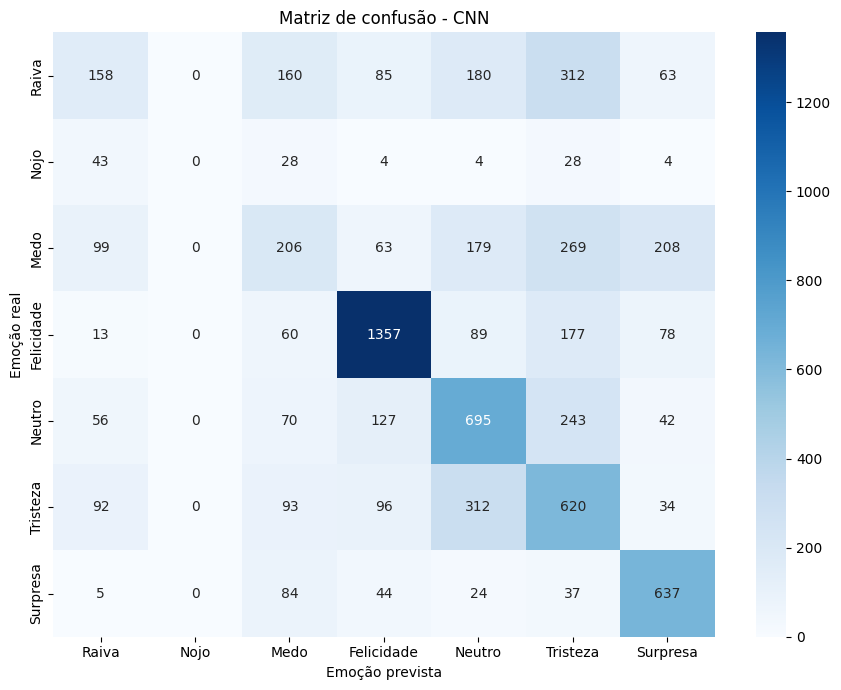

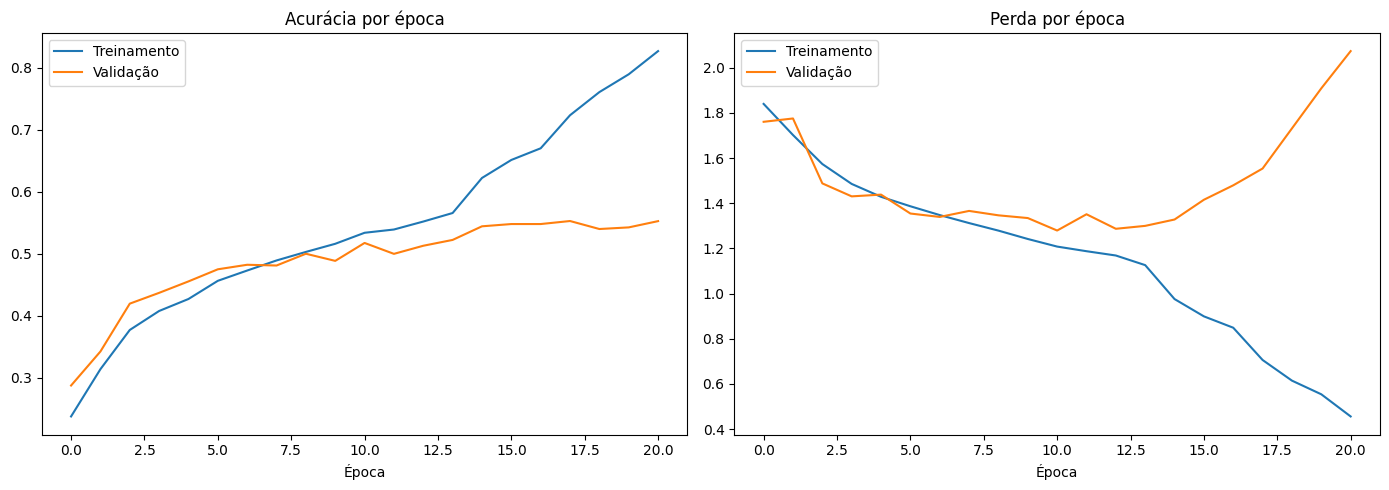

In [14]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Acurácia no teste: {test_accuracy:.4f}")
print(f"Perda no teste: {test_loss:.4f}")

y_pred = np.argmax(model.predict(X_test, batch_size=64), axis=1)
nomes_classes = ["Raiva", "Nojo", "Medo", "Felicidade", "Neutro", "Tristeza", "Surpresa"]
print(classification_report(y_test, y_pred, labels=list(range(7)), target_names=nomes_classes, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=list(range(7)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nomes_classes, yticklabels=nomes_classes)
plt.xlabel("Emoção prevista")
plt.ylabel("Emoção real")
plt.title("Matriz de confusão - CNN")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["accuracy"], label="Treinamento")
axes[0].plot(history.history["val_accuracy"], label="Validação")
axes[0].set_title("Acurácia por época")
axes[0].set_xlabel("Época")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Treinamento")
axes[1].plot(history.history["val_loss"], label="Validação")
axes[1].set_title("Perda por época")
axes[1].set_xlabel("Época")
axes[1].legend()
plt.tight_layout()
plt.show()

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5117 - loss: 1.2831
Acurácia no teste: 0.5117
Perda no teste: 1.2831
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

Relatório de classificação:
              precision    recall  f1-score   support

       Raiva       0.34      0.16      0.22       958
        Nojo       0.00      0.00      0.00       111
        Medo       0.29      0.20      0.24      1024
  Felicidade       0.76      0.76      0.76      1774
      Neutro       0.47      0.56      0.51      1233
    Tristeza       0.37      0.50      0.42      1247
    Surpresa       0.60      0.77      0.67       831

    accuracy                           0.51      7178
   macro avg       0.40      0.42      0.40      7178
weighted avg       0.49      0.51      0.49      7178



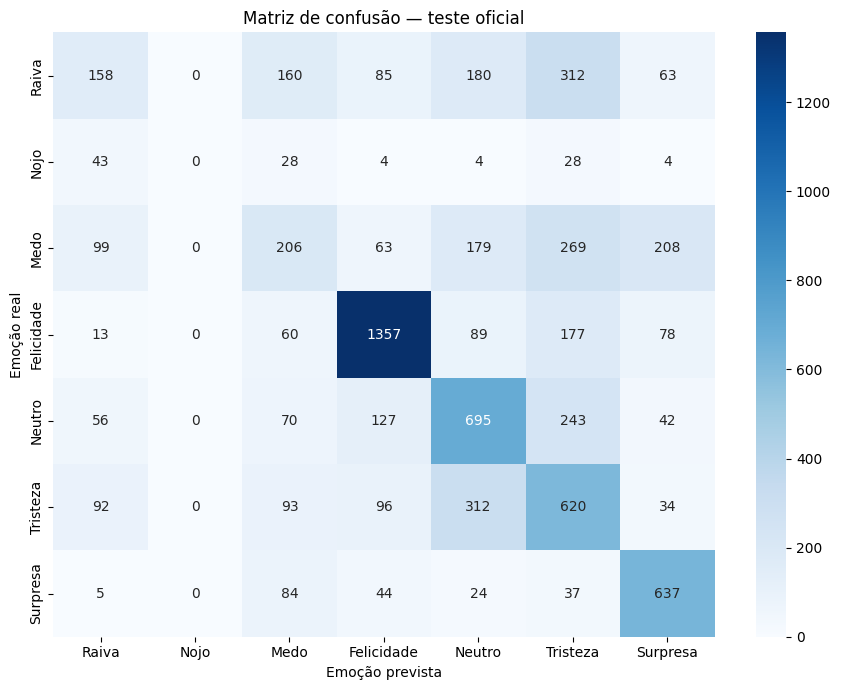

In [15]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=64, verbose=1)
print(f"Acurácia no teste: {test_accuracy:.4f}")
print(f"Perda no teste: {test_loss:.4f}")

y_pred = np.argmax(model.predict(X_test, batch_size=64, verbose=1), axis=1)
print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(7)),
    target_names=nomes_classes,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=list(range(7)))
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nomes_classes,
    yticklabels=nomes_classes
)
plt.xlabel("Emoção prevista")
plt.ylabel("Emoção real")
plt.title("Matriz de confusão — teste oficial")
plt.tight_layout()
plt.show()